# Assignment 4: Image Captioning

This assignment is somewhat short.  We want you to spend your time on the project instead!

This assignment explores models connecting different modalities - exploring a connection between images and text.  By the time you're done with this assignment, you'll have:

* investigated a few captioning techniques
* worked with CLIP embeddings for images and captions
* worked with the BLIP image captioning system



**INSTRUCTIONS:**

* Questions are always indicated as **QUESTION**, so you can search for this string to make sure you answered all of the questions. You are expected to fill out, run, and submit this notebook, as well as to answer the questions in the **answers** cells as you did in a3.  Please do **not** remove the output from your notebooks when you submit them as we'll look at the output as well as your code for grading purposes.  We cannot award points if the output cells are empty.

* **### YOUR CODE HERE** indicates that you are supposed to write code.



* \### --- Put your answer in Gradescope Q.0. Do not enter your answer here. --- ### indicates where in the Gradescope answer sheet you are supposed to write your answer. Please put your answer in the requested format. Some questions are multiple choice so you can select the appropriate answer. Other questions are fill in the blank so enter either a string or a raw number -- no executable code, for example "3,15,24" or 0.123 but NOT dict[23] or my_variable_name.

**GRADESCOPE:**

- We are **NOT** using the autograder for this assignment.

- We are using a Gradescope answer sheet to facilitate grading.

- The assignment notebook you submit must be named Assignment_4.ipynb. The very last question asks you to upload your notebook.

- Please format your input and output strings to be user friendly

- Adding comments in your code is strongly suggested but won't be graded.

- If you are stuck on a problem or do not understand a question - please come to office hours or ask questions (please don't post your code though). If it is a coding problem send a private email to your instructor.

- You can ask TAs for extra help and 1 on 1 sessions!

- You may use any libraries from the Python Standard Library for this assignment: https://docs.python.org/3/library/

**REMINDER:**
You must cite all of your uses of AI to assist in the homework.  A space is provided at the very end of the notebook to do so.

## Section A: Foundational image captioning papers



### Show & Tell

[Show and Tell: A Neural Image Caption Generator](https://arxiv.org/pdf/1411.4555.pdf) was the first step towards neural image captioning.  Fundamentally it is an encoder-decoder scheme similar to what we've seen in class.  Concretely, it uses the CNN structure of an (at the time) state of the art image classification CNN as the encoder and it uses an LSTM as a decoder.  As in the generation models in class, it continues to generate text until a special "stop" token is emitted.  After **reading** the entire paper, answer the following questions:



### Questions (Part A)

Five questions


**QUESTION:**

 A.1. (1 pt) What parts of the CNN were fine-tuned during the image caption generation training process?

    - The kernels within the CNN
    - The top feed forward layer of the CNN
    - The self-attention mechanism
    




In [2]:
### Q. A.1 --- Put your answer in Gradescope Q.1. Do not enter your answer here. --- ###
print("The top feed forward layer of the CNN")


The top feed forward layer of the CNN


**QUESTION:**

 A.2. (1 pt) What was the biggest concern when deciding how to train the model?

    - Training time
    - Overfitting
    - None of the above
    



In [1]:
### Q. A.2 --- Put your answer in Gradescope Q.2. Do not enter your answer here. --- ###
print("Overfitting")

Overfitting


**QUESTION:**

 A.3. (1 pt) How was the encoded image representation input into the decoder?

    - As an image vector at each time step
    - As the first word embedding input
    - None of the above





In [ ]:
### Q A.3. ### --- Put your answer in Gradescope Q.3. Do not enter your answer here. --- ###

**QUESTION:**

 A.4. (1 pt) Given we are "translating" from an image to a caption (without a length constraint), which evaluation metric did the authors determine was reasonable for a top line metric?

    - BLEU
    - ROUGE
    - METEOR
    - BERTScore




In [ ]:
### Q A.4. ### --- Put your answer in Gradescope Q.4. Do not enter your answer here. --- ###

**QUESTION:**

 A.5. (1 pt) What beam width is equivalent to selecting the highest probability word in each decoding step?

  - 0
  - 1
  - 5
  - vocabulary size





In [ ]:
### Q A.5. ### --- Put your answer in Gradescope Q.5. Do not enter your answer here. --- ###


### Deep Visual Alignment

[Deep Visual-Semantic Alignments for Generating Image Descriptions](https://cs.stanford.edu/people/karpathy/cvpr2015.pdf) is a fun read for which we will ask no questions.  Its critical insights are around understanding an image as a composition of regions, and building upon that understanding to construct both a caption for the whole image, but labels for its consistuent parts.

### Show, Attend & Tell

[Show, Attend & Tell](https://arxiv.org/pdf/1502.03044.pdf) applies the same "provide the decoder more context, as directly as possible" trick we've seen over the course: adding attention.  After **skimming** the paper, answer the following questions:



### Questions (Part B)

Two questions


**QUESTION:**

 B.1. (1 pt) What is the model paying attention to?
    
    - The raw pixels
    - Multiple independently trained CNNs over an object classification task, each yielding an annotation
    - Vectors are extracted from a layer of the CNN with a receptive field (image region contributing to it) smaller than the full image
    - None of the above



In [ ]:
### Q B.1 ### --- Put your answer in Gradescope Q.6. Do not enter your answer here. --- ###

**QUESTION:**

 B.2. (1 pt) What do the figures with highlight shading represent in Figures 2, 3 and 5?
    
    - The part of the image contributing to the word currently being decoded
    - The part of the image most contributing to the generated caption
    - None of the above




In [ ]:
### Q B.2. ### --- Put your answer in Gradescope Q.7. Do not enter your answer here. --- ###

### Exploring an MS COCO captioner

There are many examples of image captioners ML engineers have built on the MS COCO dataset you explored. [This one](https://replicate.com/rmokady/clip_prefix_caption) uses a (more) modern large language model as its decoder, GPT-2.  

* **Explore** the samples and play with using beam search and not.  What do you notice?

This is an example from the Show & Tell paper of a low-quality caption (see figure 5).  The GPT-2 model proposes "the car that person drove to the hospital." vs. "A yellow school bus parked in a parking lot" from the original paper. 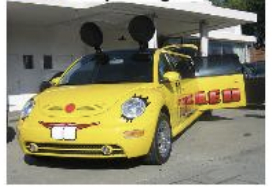

## Section B: CLIP Embeddings and Image Classification

The [CLIP paper](https://arxiv.org/pdf/2103.00020.pdf)  describes a system that emits encodings that represent both images and text captions. The system learns to match a picture with its caption so the encoding for the image and the encoding for an associated caption should have a very high cosine similarity.  Systems like DALL-E use CLIP embeddings to generate images based on a text description by using the text encoding to get the image encoding and then processing the image encoding to generate the final image.  We're going to use CLIP in the opposite direction.  Namely we're going to use CLIP embeddings to classify images, that is to score a set of captions for an image based on the image's content.


We can use the HuggingFace implementation of CLIP to experiment with this multimodal capability. Since we are not fine-tuning it we do not need access to a GPU.

In [ ]:
!pip install -q -U transformers

In [ ]:
!pip install -q diffusers --upgrade

In [ ]:
!pip install -q invisible_watermark accelerate safetensors

In [ ]:
#import tensorflow as tf
from PIL import Image
import requests
from transformers import CLIPProcessor, CLIPModel

In [ ]:
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

### Caption Creation

Now let's begin our experiment.  We're going to select two images that contain both zebras and cars.  They may contain other things as well.  We're also going to generate a set of captions that we will score.  Specifically, we'll pass the output for the captions through a softmax to give us a probability distribution over the four captions.

In [ ]:
# Example tags: animal = zebra, transport = car

urls = ["http://farm1.staticflickr.com/9/15631288_605abb3096_z.jpg", #zebras foreground, cars background
        "http://farm4.staticflickr.com/3057/3033996041_11293469b7_z.jpg"]  #zebra foreground, tiny car background
captions = ["a photo of cars",
            "a photo of a giraffe",
            "a photo of zebras in a field",
            "a photo of some zebras and cars"]

for url in urls:
    image = Image.open(requests.get(url, stream=True).raw)

    inputs = processor(
        text=captions, images=image, return_tensors="pt", padding=True
    )

    outputs = model(**inputs)
    logits_per_image = outputs.logits_per_image            # this is the image-text similarity score
    probs = logits_per_image.softmax(dim=1)                # we can take the softmax to get the label probabilities

    print()
    print(url)
    for i, caption in enumerate(captions):
        print('%40s - %.4f' % (caption, probs[0, i].detach()))

The CLIP embeddings allow us to associate captions with images.  Specifically, we can build a classifier that assigns probabilities to each of the captions.  We want the highest probability to go to the most descriptive caption out of the four captions for the given image.  Notice here that even though both images contain zebras, one of them features a line of clearly visible cars.  The other image only has one small car off in the distance.  Note that the first image with the cars scores high for the caption of ```a photo of some zebras and cars``` because the zebras and cars are very visible.  The second image scores highest for ```a photo of zebras in a field``` but the small car is less noticed but scores above a zero.

In [ ]:
# Example tags: two dogs in bike, human bike tiny dog

urls = ["http://farm1.staticflickr.com/8/10896131_6a184b48cb_z.jpg",  #2 dogs in bike basket
        "http://farm4.staticflickr.com/3082/2797293301_dd26fd613f_z.jpg"] #human and bike with tiny dog
captions = ["a photo of a dog",
            "a photo of some dogs in a basket",
            "a photo of a bike",
            "a photo of some dogs with a bike"]

for url in urls:
    image = Image.open(requests.get(url, stream=True).raw)

    inputs = processor(
        text=captions, images=image, return_tensors="pt", padding=True
    )

    outputs = model(**inputs)
    logits_per_image = outputs.logits_per_image            # this is the image-text similarity score
    probs = logits_per_image.softmax(dim=1)                # we can take the softmax to get the label probabilities

    print()
    print(url)
    for i, caption in enumerate(captions):
        print('%40s - %.4f' % (caption, probs[0, i].detach()))

Again, these two images both contain bicycles and dogs.  The first image is two dogs in a basket on the front of a bike.  While the bike is visible, the two dogs are the focus of the image.  The second image features a person with their bike.  The bike happens to contain a small dog.  We would expect the embeddings to reflect the different emphases of the photos and indeed they do.

In [ ]:
# Example tags: animal = dog, transport = bike

urls = ["http://farm1.staticflickr.com/124/405495389_d4316b1224_z.jpg",   #dog foreground and tiny bikes background
        "http://farm8.staticflickr.com/7194/6991675037_3c298541c0_z.jpg"] #motorbike foreground, many bikes and tiny dog background
captions = ["a photo of a dog",
            "a photo of a motorbike",
            "a photo of a plane",
            "a photo of some bikes"]

for url in urls:
    image = Image.open(requests.get(url, stream=True).raw)

    inputs = processor(
        text=captions, images=image, return_tensors="pt", padding=True
    )

    outputs = model(**inputs)
    logits_per_image = outputs.logits_per_image            # this is the image-text similarity score
    probs = logits_per_image.softmax(dim=1)                # we can take the softmax to get the label probabilities

    print()
    print(url)
    for i, caption in enumerate(captions):
        print('%40s - %.4f' % (caption, probs[0, i].detach()))

For the third example, the first image includes a dog in the foreground and a number of small bikes in the distant background.  You can look at the annotations associated with the image to see where these objects are located. The second image includes a motorbike/motorcycle in the the foreground but a number of bikes and a tiny dog in the background.  Again we're hand crafting these captions to include the items in the image but we want the score for the caption to reflect what's in the foreground of the image.  

Now it is your turn.  You will essentially replicate the examples above but you will do it with images **you** select.  First you need to select *two* images for processing. Go to [the COCO Explorer](https://cocodataset.org/#explore), click on two tag icons: an animal (see icon column of animals) and a mode of transportation (see icon column of ), and search. (You pick which; you might have to try a few combinations until you get multiple image results.)

Find two different images that each contain your animal and your mode of transportation.  It's okay if they contain other things as well.  If you click on the URL icon above each image, you'll see a link to the annotated image and the original (unlabeled) image. Put the original image link in the code cell below *your image 1 url* and *your image 2 url*, then create four captions that mention only one of the objects each vs both objects together. You can see the captions we created for the three examples above.  The goal is to get probabilities above 0.85 for the caption that best describes the first image and the caption that best describes the second image.

As in the examples above, you must find a pair of images with the same two objects tagged in them, but which get different results for which caption has the highest probability according to the CLIP model.

Note which object tags you used, and give a brief explanation of what looks different about the two images that you think made them get different CLIP results for the most likely caption.  Enter that explanation in the cell below.  You **do not need to enter it in the answers sheet**.  Just leave it in the notebook that you submit.

In [ ]:
# Example tags: animal = ???, transportation = ???

### YOUR CODE HERE
urls = ["your image 1 url",   #
        "your image 2 url"]   #
captions = ["caption 1",
            "caption 2",
            "caption 3",
            "caption 4"]
### END YOUR CODE


for url in urls:
    image = Image.open(requests.get(url, stream=True).raw)

    inputs = processor(
        text=captions, images=image, return_tensors="pt", padding=True
    )

    outputs = model(**inputs)
    logits_per_image = outputs.logits_per_image            # this is the image-text similarity score
    probs = logits_per_image.softmax(dim=1)                # we can take the softmax to get the label probabilities

    print()
    print(url)
    for i, caption in enumerate(captions):
        print('%40s - %.4f' % (caption, probs[0, i].detach()))

### Questions (Part C)

Five Questions

**QUESTION:**

 C.1. (2 pt) What is the animal tag you selected? (Put the answer in the answers cell in a quoted string; it should match the value shown in your output in this notebook.)



In [ ]:
### QC.1. ### --- Put your answer in Gradescope Q.8. Do not enter your answer here. --- ###

**QUESTION:**

 C.2. (2 pt) What is the transportation tag you selected?  (Put the answer in the answers cell in a quoted string; it should match the value shown in your output in this notebook.)



In [ ]:
### QC.2. ### --- Put your answer in Gradescope Q.9. Do not enter your answer here. --- ###

**QUESTION:**

 C.3. (2 pt) What is the probability associated with the most likely caption for image 1?

 (Copy and paste the decimal value for the final validation loss, to 5 significant digits, e.g. a number like 0.56781 or 0.87632. Put the answer in the answers cell; it should match the value shown in your output in this notebook.)



In [ ]:
### Q C.3. ### --- Put your answer in Gradescope Q.10. Do not enter your answer here. --- ###

**QUESTION:**

 C.4. (2 pt) What is the probability associated with the most likely caption for image 2?

 (Copy and paste the decimal value for the final validation loss, to 5 significant digits, e.g. a number like 0.56781 or 0.87632. Put the answer in the answers cell; it should match the value shown in your output in this notebook.)



In [ ]:
### Q C.4. ### --- Put your answer in Gradescope Q.11. Do not enter your answer here. --- ###

**QUESTION:**

 C.5. (2 pt) Why do you think the differences between your two images are reflected in the 4 captions you produced?

 (Write a two to four sentence explanation. Put the answer in the answers cell between the triple quotes.)



In [ ]:
### Q C.5. ### --- Put your answer in Gradescope Q.12. Do not enter your answer here. --- ###

### Caption Evaluation (another angle)

We used CLIP to evaluate the captions and to select the best caption given a choice from four.  Now let's use a model named [BLIP](https://huggingface.co/docs/transformers/en/model_doc/blip) to generate the caption for an image.

In [ ]:
!pip install -q invisible_watermark transformers accelerate safetensors

In [ ]:
from transformers import AutoProcessor, BlipForConditionalGeneration

In [ ]:
bl_processor = AutoProcessor.from_pretrained("Salesforce/blip-image-captioning-base")

bl_model = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base")


Now let's begin our experiment.  We're going re-use the two images you used in the previous CLIP exercise. Your images contain both the animal and the type of transporation you selected.  They may contain other things as well.  We're also going to generate a caption for each one that we will score.  Specifically, we'll pass the output for the captions through a softmax to give us a probability distribution over the four captions.

First, let's generate a caption for your first image, the one in C3.  Paste the image URL into the spot below.

In [ ]:
#image one URL

### YOUR CODE HERE
url = "YOUR IMAGE 1 URL HERE"
### END YOUR CODE

image = Image.open(requests.get(url, stream=True).raw)

text = "A picture of"

inputs = bl_processor(images=image, text=text, return_tensors="pt")


outputs = bl_model.generate(**inputs, max_new_tokens=25)

print(bl_processor.decode(outputs[0], skip_special_tokens=True))


Next, let's generate a caption for your second image, the one in C4.  Paste the image URL into the spot below.

In [ ]:
#image two URL

### YOUR CODE HERE
url = "YOUR IMAGE 2 URL HERE"
### END YOUR CODE

image = Image.open(requests.get(url, stream=True).raw)

text = "A picture of"

inputs = bl_processor(images=image, text=text, return_tensors="pt")

outputs = bl_model.generate(**inputs, max_new_tokens=25)

print(bl_processor.decode(outputs[0], skip_special_tokens=True))

Now lets see how the captions you just generated work as describing your images.  We're going to use CLIP to evaluate the captions you just generated.  Fill out the cell below by copying the URLs for the images you selected with the animal and the transportation. Now copy the BLIP caption for your first image and past it in to caption #1.  Copy the the BLIP caption for your second image and past it in to caption #3. Now take the highest scoring caption for image #1 from question 3c and paste that caption into slot 2.  Then take the highest scoring caption for image #2 from question 4c and paste that caption into slot 4. Now rerun CLIP and look at the scores.  

In [ ]:
# Example tags from section C: animal = ???, transportation = ???

### YOUR CODE HERE
urls = ["your image 1 url",   #
        "your image 2 url"] #
captions = ["caption 1",
            "caption 2",
            "caption 3",
            "caption 4"]
### END YOUR CODE
            #

for url in urls:
    image = Image.open(requests.get(url, stream=True).raw)

    inputs = processor(
        text=captions, images=image, return_tensors="pt", padding=True
    )

    outputs = model(**inputs)
    logits_per_image = outputs.logits_per_image  # this is the image-text similarity score
    probs = logits_per_image.softmax(dim=1)                # we can take the softmax to get the label probabilities

    print()
    print(url)
    for i, caption in enumerate(captions):
        print('%40s - %.4f' % (caption, probs[0, i].detach()))


### Questions (Part D)

Five questions

**QUESTION:**

 D.1. (2 pt) Does the BLIP caption win or do other captions win for image #1?

   - BLIP Caption
   - Other caption
   - Tied


In [ ]:
### Q D.1. ### --- Put your answer in Gradescope Q.13. Do not enter your answer here. --- ###

**QUESTION:**

 D.2. (2 pt) Does the BLIP caption win or do other captions win for image #2?

   - BLIP Caption
   - Other caption
   - Tied


In [ ]:
### Q D.2. ### --- Put your answer in Gradescope Q.14. Do not enter your answer here. --- ###

**QUESTION:**

 D.3. (2 pt) What is the probability associated with the most likely caption for image #1?  

 (Copy and paste the decimal value for the final validation loss, to 5 significant digits, e.g. a number like 0.56781 or 0.87632. Put the answer in the answers cell; it should match the value shown in your output in this notebook.)



In [ ]:
### QD.3. ### --- Put your answer in Gradescope Q.15. Do not enter your answer here. --- ###

**QUESTION:**

 D.4. (2 pt) What is the probability associated with the most likely caption for image #2?  

 (Copy and paste the decimal value for the final validation loss, to 5 significant digits, e.g. a number like 0.56781 or 0.87632. Put the answer in the answers cell; it should match the value shown in your output in this notebook.)


In [ ]:
### Q D.4. ### --- Put your answer in Gradescope Q.16. Do not enter your answer here. --- ###

**QUESTION:**

 D.5. (2 pt) Why do you think the winning caption scored higher than the 3 others?

 (Put your two to four sentence answer in the answers cell.)



In [ ]:
### QD.5. ### --- Put your answer in Gradescope Q.17. Do not enter your answer here. --- ###

## AI Citation Section

*   List item
*   List item




*DOUBLE CLICK HERE TO ADD GEN AI CITATIONS*

and cite the models you have used and what you've used them to do.

Cite models as follows (roughly equivalent to Chicago Manual of Style format)

Task or Prompt, Model, Publisher, Date, URL to conversation if publicly available, for example:

Polish wording, Gemini3, Google, 1/1/26, https://chatgpt.com/share/66fb0ff3-7280-8009-93a9-d956f41234567b


To complete the assignment, download this completed notebook as an .ipynb file to your laptop and then upload that .ipynb file into Gradescope using the very last answer cell in the answers sheet.  We expect to find a file named Assignment_4.ipynb in Gradescope associated with you.

**It is your responsibility to make sure that you have uploaded the correct file with your code, the outputs of running your code and other cells, and the answer cells filled in by you.  We will grade you based on a combination of the answer cells and the code and output of the code you have written.**

## Yay, you're done with your 266 homework.  Now focus on your project!